# Facial Emotion Recognition with CNN — FER2013
## Starter Notebook

</div>

---
## 📖 About the Dataset

**Source:** [FER2013 on Kaggle](https://www.kaggle.com/datasets/msambare/fer2013)

FER2013 (*Facial Expression Recognition 2013*) was introduced in a Kaggle competition in 2013 as part of the ICML workshop *"Challenges in Representation Learning"*. The faces were collected automatically from Google image search, so they are **real-world faces**: different ages, poses, lighting, glasses, hands covering the face, etc.

| Property | Value |
|---|---|
| Total images | ~35,900 |
| Image size | **48 × 48 pixels** |
| Color | **Grayscale** (1 channel) |
| Classes | **7 emotions** |
| Train / Test | ~28,700 / ~7,200 images |
| Format | `.jpg` files in one folder per class |

**The 7 classes:** `angry` 😠 · `disgust` 🤢 · `fear` 😨 · `happy` 😄 · `neutral` 😐 · `sad` 😢 · `surprise` 😲

**Folder structure:**
```
fer2013/
├── train/
│   ├── angry/     ├── disgust/   ├── fear/   ├── happy/
│   ├── neutral/   ├── sad/       └── surprise/
└── test/
    └── (same 7 folders)
```

### ⚠️ Things to know before you start
1. **The classes are imbalanced** — `happy` has ~7,000 training images while `disgust` has only ~400. A model can get "good" accuracy just by ignoring the rare classes, so look at **per-class** results, not only overall accuracy.
2. **The task is hard** — the images are small and blurry, and some emotions look alike (fear vs. surprise, sad vs. neutral). Human accuracy on this dataset is estimated at only **~65%**, so don't expect 95%!
3. **There is no validation set** — we will create one from the training set.
4. **Some labels are noisy** — a few images are mislabeled or are not faces at all.

<div dir="rtl">

---
## 📖 نبذة عن البيانات

**المصدر:** [FER2013 على Kaggle](https://www.kaggle.com/datasets/msambare/fer2013)

بيانات FER2013 (*التعرّف على تعابير الوجه 2013*) نُشرت في مسابقة على Kaggle عام 2013 ضمن ورشة ICML بعنوان *"تحديات تعلّم التمثيلات"*. جُمعت الوجوه تلقائياً من بحث صور Google، لذلك هي **وجوه من الواقع**: أعمار مختلفة، وضعيات مختلفة، إضاءة متفاوتة، نظارات، أيدٍ تغطي الوجه... إلخ.

| الخاصية | القيمة |
|---|---|
| عدد الصور الكلي | حوالي 35,900 |
| حجم الصورة | **48 × 48 بكسل** |
| الألوان | **رمادية (Grayscale)** — قناة واحدة |
| عدد الأصناف | **7 مشاعر** |
| تدريب / اختبار | حوالي 28,700 / 7,200 صورة |
| الصيغة | ملفات `.jpg` في مجلد لكل صنف |

**الأصناف السبعة:** `angry` غضب 😠 · `disgust` اشمئزاز 🤢 · `fear` خوف 😨 · `happy` سعادة 😄 · `neutral` محايد 😐 · `sad` حزن 😢 · `surprise` مفاجأة 😲

### ⚠️ أمور مهمة قبل البدء
1. **الأصناف غير متوازنة** — صنف `happy` فيه حوالي 7,000 صورة تدريب بينما `disgust` فيه حوالي 400 فقط. النموذج قد يحصل على دقة "جيدة" وهو يتجاهل الأصناف النادرة، لذلك انظر إلى النتائج **لكل صنف** وليس الدقة الكلية فقط.
2. **المهمة صعبة** — الصور صغيرة وغير واضحة، وبعض المشاعر متشابهة (الخوف والمفاجأة، الحزن والمحايد). دقة الإنسان على هذه البيانات تُقدّر بحوالي **65%** فقط، فلا تتوقع 95%!
3. **لا توجد بيانات تحقق (validation)** — سننشئها من بيانات التدريب.
4. **بعض التسميات فيها أخطاء** — بعض الصور مصنّفة خطأ أو ليست وجوهاً أصلاً.

</div>

---
## 1. Setup
> In Colab, enable the GPU: **Runtime → Change runtime type → T4 GPU**

<div dir="rtl">

## 1. الإعداد
> في Colab فعّل الـ GPU من: **Runtime → Change runtime type → T4 GPU**

</div>

In [18]:
# Install kagglehub (used to download datasets from Kaggle)
# تثبيت مكتبة kagglehub لتحميل البيانات من Kaggle
!pip install -q kagglehub

In [19]:
import os
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split

# ---- Reproducibility: same random results every run ----
# ---- تثبيت العشوائية: نفس النتائج في كل تشغيل ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use the GPU if available, otherwise the CPU
# استخدم الـ GPU إن وُجد، وإلا الـ CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 2. Download the Data
We use `kagglehub` to download the dataset directly from Kaggle.
> If you get an authentication error: in Colab open 🔑 **Secrets** and add `KAGGLE_USERNAME` and `KAGGLE_KEY` (from Kaggle → Settings → API → Create New Token).

<div dir="rtl">

## 2. تحميل البيانات
نستخدم `kagglehub` لتحميل البيانات مباشرة من Kaggle.
> إذا ظهر خطأ في الصلاحيات: من Colab افتح 🔑 **Secrets** وأضف `KAGGLE_USERNAME` و `KAGGLE_KEY` (من Kaggle ← Settings ← API ← Create New Token).

</div>

In [20]:
import kagglehub

# Download the dataset (it is cached, so running again is instant)
# تحميل البيانات (تُحفظ مؤقتاً، فإعادة التشغيل تكون فورية)
path = kagglehub.dataset_download("msambare/fer2013")
print("Downloaded to:", path)

# Locate the train/ and test/ folders
# تحديد مسار مجلدي التدريب والاختبار
TRAIN_DIR = os.path.join(path, "train")
TEST_DIR  = os.path.join(path, "test")
print("Train folder:", TRAIN_DIR, "| exists:", os.path.isdir(TRAIN_DIR))
print("Test folder: ", TEST_DIR,  "| exists:", os.path.isdir(TEST_DIR))
print("Class folders:", sorted(os.listdir(TRAIN_DIR)))

Using Colab cache for faster access to the 'fer2013' dataset.
Downloaded to: /kaggle/input/fer2013
Train folder: /kaggle/input/fer2013/train | exists: True
Test folder:  /kaggle/input/fer2013/test | exists: True
Class folders: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## 3. Explore the Data

<div dir="rtl">

## 3. استكشاف البيانات

</div>

In [21]:
# ImageFolder reads a "one folder per class" structure:
# the folder name becomes the class name, and each image gets that label.
# ImageFolder يقرأ البيانات المنظّمة بمجلد لكل صنف:
# اسم المجلد يصبح اسم الصنف، وكل صورة تأخذ تسمية مجلدها.
raw_train = datasets.ImageFolder(TRAIN_DIR)
raw_test  = datasets.ImageFolder(TEST_DIR)

CLASS_NAMES = raw_train.classes          # ['angry', 'disgust', 'fear', ...]
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", dict(enumerate(CLASS_NAMES)))
print("Train images:", len(raw_train))
print("Test images: ", len(raw_test))

# Check the size and mode of one image (L = grayscale)
# فحص حجم ونوع صورة واحدة (L تعني رمادية)
img, label = raw_train[0]
print("Image size:", img.size, "| mode:", img.mode, "| label:", CLASS_NAMES[label])

Classes: {0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'neutral', 5: 'sad', 6: 'surprise'}
Train images: 28709
Test images:  7178
Image size: (48, 48) | mode: RGB | label: angry


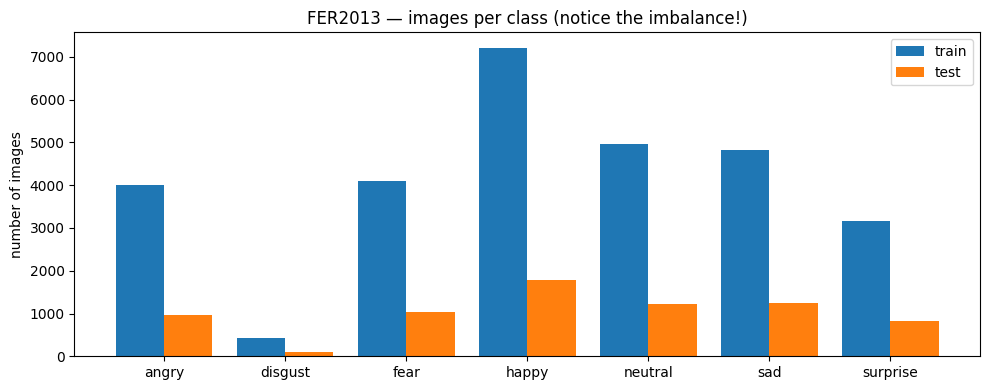

angry      train:  3995   test:   958
disgust    train:   436   test:   111
fear       train:  4097   test:  1024
happy      train:  7215   test:  1774
neutral    train:  4965   test:  1233
sad        train:  4830   test:  1247
surprise   train:  3171   test:   831


In [22]:
# ---- Class distribution: how many images per emotion? ----
# ---- توزيع الأصناف: كم صورة لكل شعور؟ ----
train_counts = Counter(raw_train.targets)
test_counts  = Counter(raw_test.targets)

x = np.arange(NUM_CLASSES)
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, [train_counts[i] for i in range(NUM_CLASSES)], width=0.4, label="train")
plt.bar(x + 0.2, [test_counts[i]  for i in range(NUM_CLASSES)], width=0.4, label="test")
plt.xticks(x, CLASS_NAMES)
plt.ylabel("number of images")
plt.title("FER2013 — images per class (notice the imbalance!)")
plt.legend()
plt.tight_layout()
plt.show()

for i, name in enumerate(CLASS_NAMES):
    print(f"{name:<10} train: {train_counts[i]:>5}   test: {test_counts[i]:>5}")

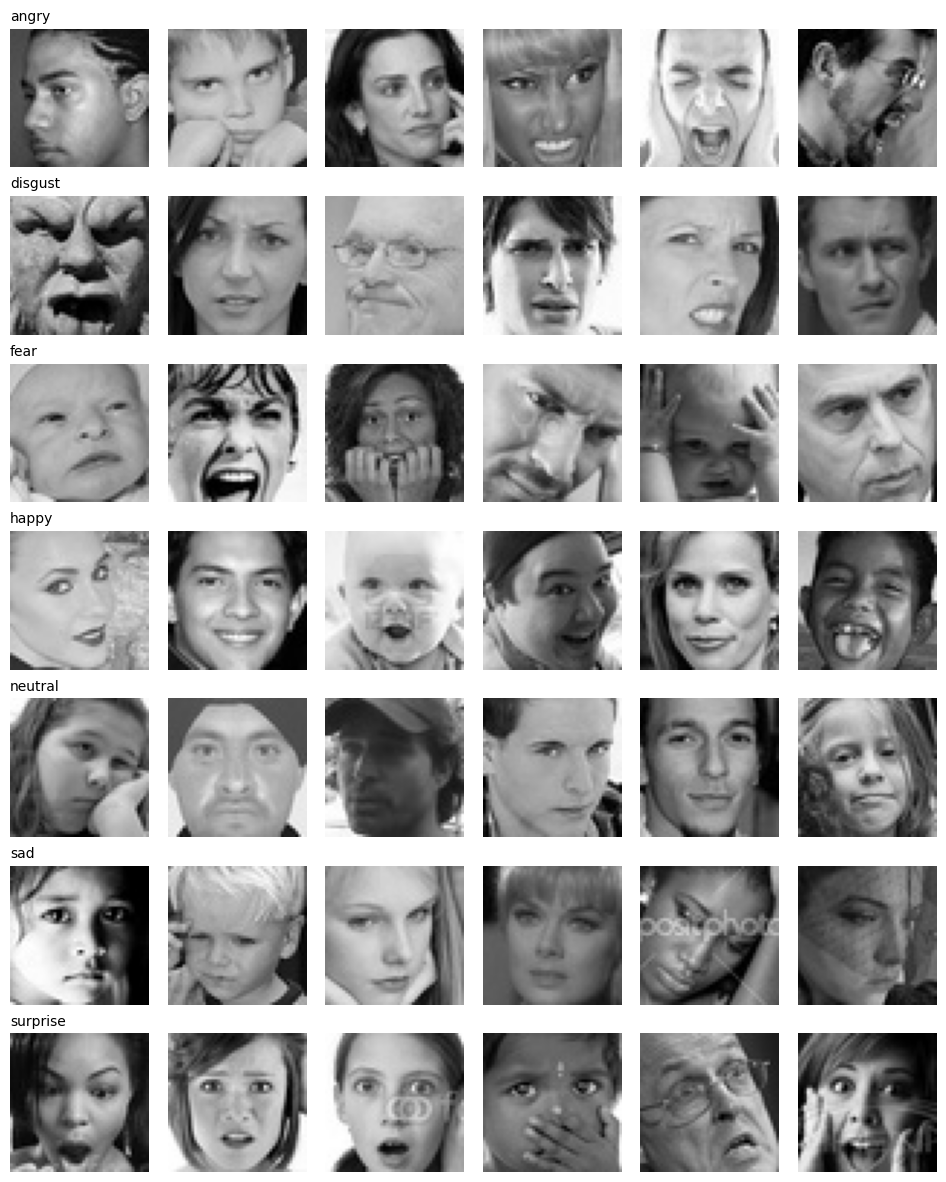

In [23]:
# ---- Show random examples from each class ----
# ---- عرض أمثلة عشوائية من كل صنف ----
N_PER_CLASS = 6
train_targets = np.array(raw_train.targets)

fig, axes = plt.subplots(NUM_CLASSES, N_PER_CLASS, figsize=(N_PER_CLASS * 1.6, NUM_CLASSES * 1.7))
for c in range(NUM_CLASSES):
    # pick random image indices that belong to class c
    # اختيار صور عشوائية تنتمي للصنف c
    idxs = np.random.choice(np.where(train_targets == c)[0], N_PER_CLASS, replace=False)
    for j, idx in enumerate(idxs):
        img, _ = raw_train[idx]
        axes[c, j].imshow(img, cmap="gray")
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=10)
plt.tight_layout()
plt.show()

In [24]:
# ===== 4. Prepare the data =====
# تدريب / تحقق / اختبار

from torchvision import models
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report

# EfficientNet expects 3-channel images and 224x224 input
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Same images, different transforms
full_train_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
full_train_eval = datasets.ImageFolder(TRAIN_DIR, transform=test_transform)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transform)

# Create validation set from training data
indices = np.arange(len(raw_train))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=raw_train.targets
)

train_dataset = Subset(full_train_aug, train_idx)
val_dataset = Subset(full_train_eval, val_idx)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 22967
Validation: 5742
Test: 7178


In [25]:
## ========== Experiment 1:Custom CNN — Train from Scratch =====

# Build the CNN
cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d((1, 1)),

    nn.Flatten(),
    nn.Linear(128, NUM_CLASSES)
).to(device)


# Function to train and evaluate either model
def train_and_evaluate(model, optimizer, name, epochs=3):

    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        model.train()
        running_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"{name} Epoch {epoch+1}/{epochs} "
              f"| Loss: {running_loss/len(train_loader):.4f}")

    # Final test accuracy
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = outputs.max(1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    print(f"\n{name} Test Accuracy: {accuracy:.2f}%")

    return accuracy


# Train CNN
optimizer_cnn = optim.Adam(cnn.parameters(), lr=0.001)

cnn_accuracy = train_and_evaluate(
    cnn, optimizer_cnn, "Custom CNN", epochs=3
)


print("Using device:", device)

Custom CNN Epoch 1/3 | Loss: 1.7986
Custom CNN Epoch 2/3 | Loss: 1.7885
Custom CNN Epoch 3/3 | Loss: 1.7818

Custom CNN Test Accuracy: 26.30%
Using device: cuda


EfficientNet-B0 Epoch 1/3 | Loss: 1.6156
EfficientNet-B0 Epoch 2/3 | Loss: 1.5454
EfficientNet-B0 Epoch 3/3 | Loss: 1.5334

EfficientNet-B0 Test Accuracy: 42.39%

===== FINAL COMPARISON =====
Custom CNN Accuracy:      26.30%
EfficientNet-B0 Accuracy: 42.39%


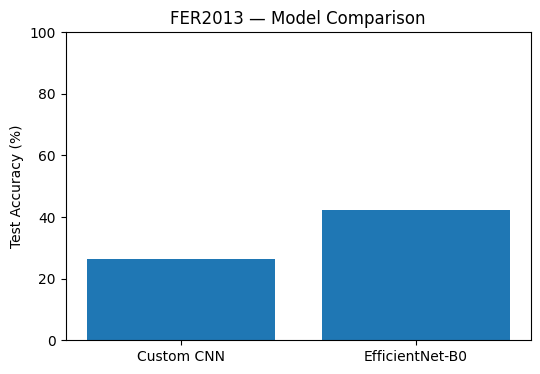

In [26]:
# ===== ===== Experiment 2: Pretrained EfficientNet-B0 =====

# Load pretrained model
weights = models.EfficientNet_B0_Weights.DEFAULT
efficientnet = models.efficientnet_b0(weights=weights)

# Freeze the pretrained backbone
for param in efficientnet.parameters():
    param.requires_grad = False

# Replace final classification layer (7 classes)
in_features = efficientnet.classifier[1].in_features
efficientnet.classifier[1] = nn.Linear(
    in_features, NUM_CLASSES
)

efficientnet = efficientnet.to(device)

# Train only the new classification head
optimizer_eff = optim.Adam(
    efficientnet.classifier[1].parameters(),
    lr=0.001
)

efficientnet_accuracy = train_and_evaluate(
    efficientnet, optimizer_eff, "EfficientNet-B0", epochs=3
)


# ===== 7. Compare Results =====

print("\n===== FINAL COMPARISON =====")
print(f"Custom CNN Accuracy:      {cnn_accuracy:.2f}%")
print(f"EfficientNet-B0 Accuracy: {efficientnet_accuracy:.2f}%")

plt.figure(figsize=(6, 4))
plt.bar(
    ["Custom CNN", "EfficientNet-B0"],
    [cnn_accuracy, efficientnet_accuracy]
)
plt.ylabel("Test Accuracy (%)")
plt.title("FER2013 — Model Comparison")
plt.ylim(0, 100)
plt.show()

EfficientNet-B0 Partial Fine-Tuning Epoch 1/3 | Loss: 1.4973
EfficientNet-B0 Partial Fine-Tuning Epoch 2/3 | Loss: 1.3166
EfficientNet-B0 Partial Fine-Tuning Epoch 3/3 | Loss: 1.2445

EfficientNet-B0 Partial Fine-Tuning Test Accuracy: 52.98%

===== CURRENT MODEL COMPARISON =====
Custom CNN: 26.30%
EfficientNet-B0 Feature Extraction: 42.39%
EfficientNet-B0 Partial Fine-Tuning: 52.98%


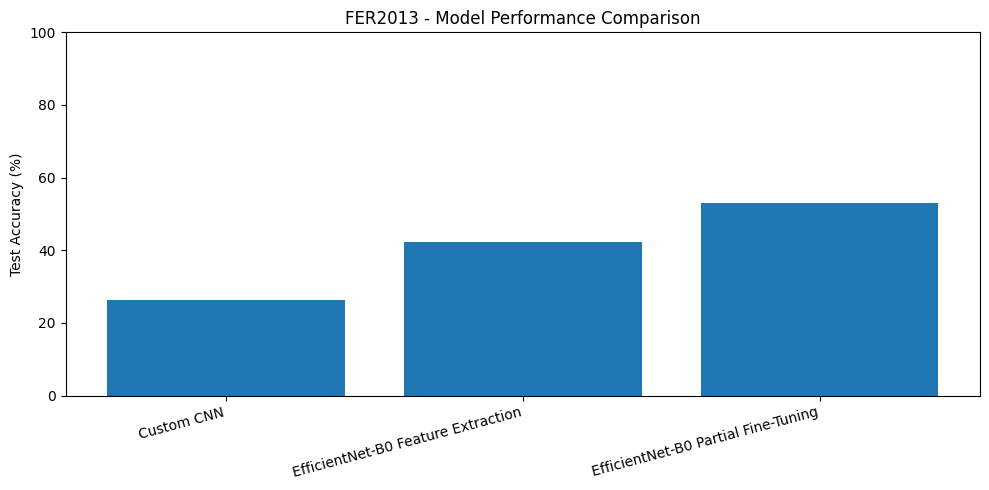

In [27]:
# ===== Experiment 3: EfficientNet-B0 Partial Fine-Tuning =====

# 1. Import Libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
import matplotlib.pyplot as plt

# 2. Load Pretrained EfficientNet-B0
partial_model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

# 3. Freeze All Pretrained Layers
for param in partial_model.parameters():
    param.requires_grad = False

# 4. Unfreeze Last Two Feature Blocks
for param in partial_model.features[7:].parameters():
    param.requires_grad = True

# 5. Replace Classification Head (7 Classes)
in_features = partial_model.classifier[1].in_features
partial_model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

partial_model = partial_model.to(device)

# 6. Set Optimizer and Learning Rates
optimizer_partial = optim.Adam([
    {"params": partial_model.features[7:].parameters(), "lr": 0.0001},
    {"params": partial_model.classifier[1].parameters(), "lr": 0.001}
])

# 7. Train and Evaluate
partial_accuracy = train_and_evaluate(
    partial_model,
    optimizer_partial,
    "EfficientNet-B0 Partial Fine-Tuning",
    epochs=3
)

# 8. Compare Current Experiments
model_names = [
    "Custom CNN",
    "EfficientNet-B0 Feature Extraction",
    "EfficientNet-B0 Partial Fine-Tuning"
]

accuracies = [
    cnn_accuracy,
    efficientnet_accuracy,
    partial_accuracy
]

print("\n===== CURRENT MODEL COMPARISON =====")

for name, accuracy in zip(model_names, accuracies):
    print(f"{name}: {accuracy:.2f}%")

plt.figure(figsize=(10, 5))
plt.bar(model_names, accuracies)
plt.ylabel("Test Accuracy (%)")
plt.title("FER2013 - Model Performance Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


===== Custom CNN =====
              precision    recall  f1-score   support

       angry       0.20      0.00      0.00       958
     disgust       0.00      0.00      0.00       111
        fear       0.38      0.00      0.01      1024
       happy       0.26      0.90      0.40      1774
     neutral       0.24      0.15      0.19      1233
         sad       0.00      0.00      0.00      1247
    surprise       0.43      0.12      0.19       831

    accuracy                           0.26      7178
   macro avg       0.22      0.17      0.11      7178
weighted avg       0.24      0.26      0.16      7178


===== EfficientNet-B0 Feature Extraction =====
              precision    recall  f1-score   support

       angry       0.41      0.20      0.27       958
     disgust       0.17      0.01      0.02       111
        fear       0.27      0.21      0.24      1024
       happy       0.50      0.68      0.58      1774
     neutral       0.36      0.43      0.39      1233
      

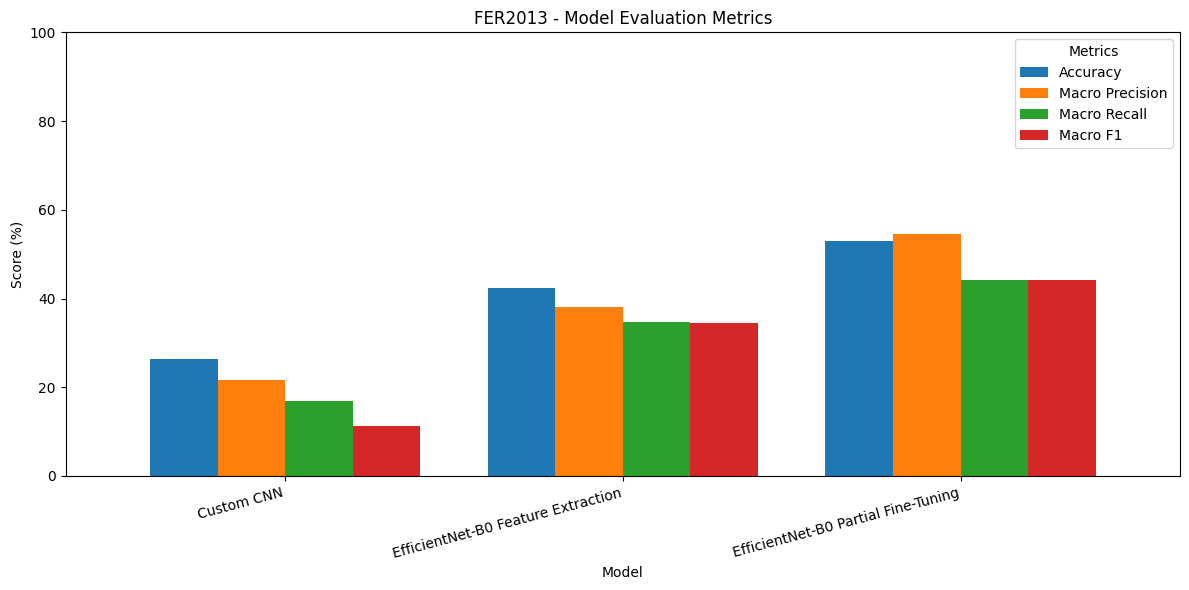

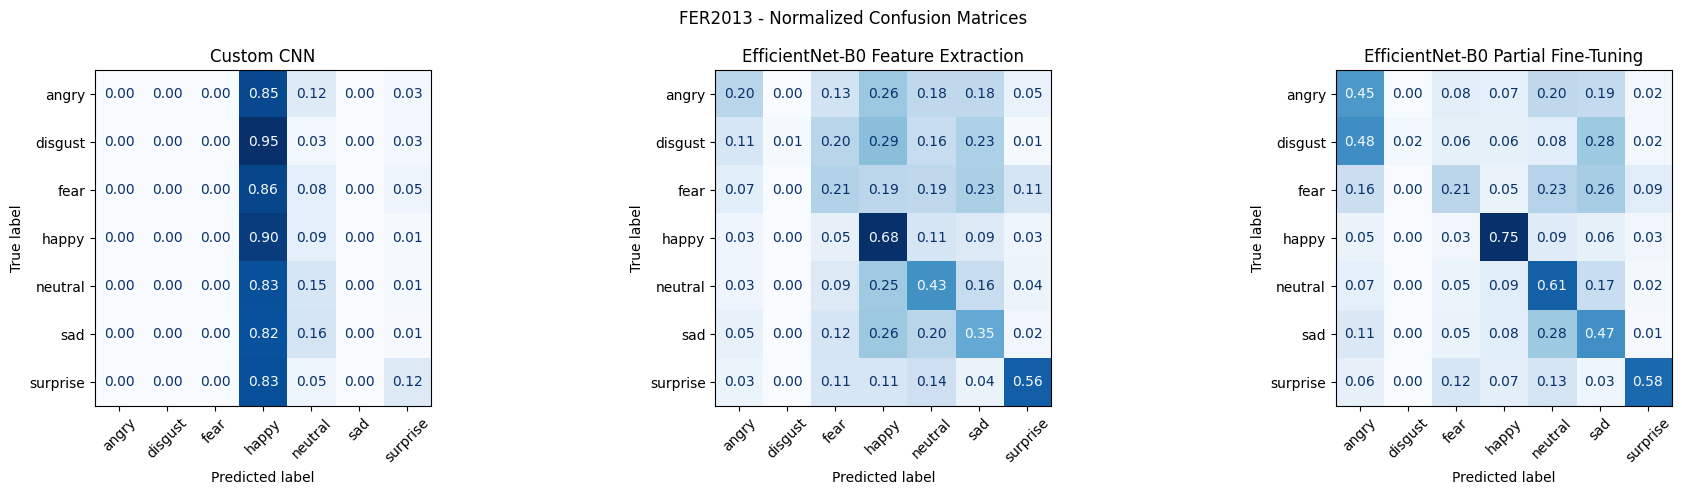


===== BEST MODEL BY MACRO F1 =====
Model: EfficientNet-B0 Partial Fine-Tuning
Macro F1: 44.18%


In [28]:
# ===== FER2013: Multi-Metric Model Evaluation =====
# Accuracy, Macro Precision, Macro Recall, Macro F1, Confusion Matrices

import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Models to compare
models_to_compare = {
    "Custom CNN": cnn,
    "EfficientNet-B0 Feature Extraction": efficientnet,
    "EfficientNet-B0 Partial Fine-Tuning": partial_model
}

evaluation_results = []
confusion_matrices = {}

# 2. Evaluate all models
for name, current_model in models_to_compare.items():

    current_model.eval()
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = current_model(images)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    # Calculate four evaluation metrics
    accuracy = accuracy_score(all_labels, all_predictions)

    precision = precision_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    f1 = f1_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy * 100,
        "Macro Precision": precision * 100,
        "Macro Recall": recall * 100,
        "Macro F1": f1 * 100
    })

    # Normalized confusion matrix
    confusion_matrices[name] = confusion_matrix(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        normalize="true"
    )

    print(f"\n===== {name} =====")
    print(classification_report(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0
    ))

# 3. Results comparison table
results_df = pd.DataFrame(evaluation_results)

print("\n===== MODEL EVALUATION COMPARISON =====")
print(results_df.round(2).to_string(index=False))

# 4. Four-metric comparison chart
ax = results_df.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("FER2013 - Model Evaluation Metrics")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

# 5. Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, (name, cm) in zip(
    axes, confusion_matrices.items()
):
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format=".2f",
        colorbar=False
    )

    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("FER2013 - Normalized Confusion Matrices")
plt.tight_layout()
plt.show()

# 6. Identify highest Macro F1
best_model = results_df.loc[results_df["Macro F1"].idxmax()]

print("\n===== BEST MODEL BY MACRO F1 =====")
print("Model:", best_model["Model"])
print(f"Macro F1: {best_model['Macro F1']:.2f}%")

In [29]:
# Save the best model (EfficientNet-B0 Partial Fine-Tuning)

import torch
from google.colab import files

model_filename = "FER2013_EfficientNetB0_Partial_Finetuning.pth"

# Save model weights and configuration
torch.save({
    "model_state_dict": partial_model.state_dict(),
    "class_names": CLASS_NAMES,
    "num_classes": NUM_CLASSES,
    "image_size": 224,
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225],
    "model_name": "efficientnet_b0"
}, model_filename)

print("Model saved:", model_filename)

# Download the model for optimization and deployment
files.download(model_filename)

Model saved: FER2013_EfficientNetB0_Partial_Finetuning.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# Model Optimization - FP32 to INT8

!pip install -q onnx onnxruntime

import os
import copy
import torch
import numpy as np
import onnx

from onnxruntime.quantization import (
    quantize_static,
    CalibrationDataReader,
    QuantFormat,
    QuantType
)
from onnxruntime.quantization.shape_inference import quant_pre_process

# Model files
fp32_path = "FER2013_EfficientNet_FP32.onnx"
prepared_path = "FER2013_EfficientNet_Prepared.onnx"
int8_path = "FER2013_EfficientNet_INT8.onnx"

# Export trained model
model_fp32 = copy.deepcopy(partial_model).cpu().eval()

torch.onnx.export(
    model_fp32,
    torch.randn(1, 3, 224, 224),
    fp32_path,
    input_names=["images"],
    output_names=["logits"],
    dynamic_axes={"images": {0: "batch"}, "logits": {0: "batch"}},
    opset_version=17,
    dynamo=False
)

# Prepare ONNX model
quant_pre_process(
    fp32_path,
    prepared_path,
    skip_symbolic_shape=True
)

# Select 350 training images for calibration
rng = np.random.default_rng(42)
targets = np.array(raw_train.targets)
indices = np.array(train_idx)

calibration_indices = []

for class_id in range(NUM_CLASSES):
    class_indices = indices[targets[indices] == class_id]
    selected = rng.choice(class_indices, size=50, replace=False)
    calibration_indices.extend(selected)

# Calibration reader
class CalibrationReader(CalibrationDataReader):
    def __init__(self):
        self.indices = iter(calibration_indices)

    def get_next(self):
        index = next(self.indices, None)
        if index is None:
            return None

        image, _ = full_train_eval[int(index)]
        return {"images": image.unsqueeze(0).numpy().astype(np.float32)}

# Apply INT8 quantization
quantize_static(
    model_input=prepared_path,
    model_output=int8_path,
    calibration_data_reader=CalibrationReader(),
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QUInt8,
    weight_type=QuantType.QInt8,
    per_channel=True,
    reduce_range=True,
    op_types_to_quantize=["Conv", "Gemm"]
)

# Verify models
onnx.checker.check_model(fp32_path)
onnx.checker.check_model(int8_path)

# Compare model sizes
fp32_size = os.path.getsize(fp32_path) / (1024 ** 2)
int8_size = os.path.getsize(int8_path) / (1024 ** 2)
reduction = (1 - int8_size / fp32_size) * 100

print("\n===== OPTIMIZATION RESULTS =====")
print(f"Calibration Images: {len(calibration_indices)}")
print(f"FP32 Size: {fp32_size:.2f} MB")
print(f"INT8 Size: {int8_size:.2f} MB")
print(f"Size Reduction: {reduction:.2f}%")
print("Optimization completed.")

/tmp/ipykernel_285/2972650069.py:27: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(



===== OPTIMIZATION RESULTS =====
Calibration Images: 350
FP32 Size: 15.31 MB
INT8 Size: 4.58 MB
Size Reduction: 70.10%
Optimization completed.


In [31]:
# FP32 vs INT8 - Evaluation

import os
import time
import numpy as np
import pandas as pd
import onnxruntime as ort

from sklearn.metrics import accuracy_score, f1_score

# Load ONNX models
fp32_session = ort.InferenceSession(
    fp32_path,
    providers=["CPUExecutionProvider"]
)

int8_session = ort.InferenceSession(
    int8_path,
    providers=["CPUExecutionProvider"]
)

sessions = {
    "FP32": fp32_session,
    "INT8": int8_session
}

results = []
sample_image = None

for name, session in sessions.items():
    input_name = session.get_inputs()[0].name

    all_labels = []
    all_predictions = []

    print(f"\nEvaluating {name}...")

    # Full test set evaluation
    for images, labels in test_loader:
        images_np = images.numpy().astype(np.float32)

        if sample_image is None:
            sample_image = images_np[:1].copy()

        outputs = session.run(None, {input_name: images_np})[0]
        predictions = np.argmax(outputs, axis=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions)

    accuracy = accuracy_score(all_labels, all_predictions) * 100
    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    ) * 100

    # Warm-up
    for _ in range(10):
        session.run(None, {input_name: sample_image})

    # Latency measurement
    times = []

    for _ in range(50):
        start = time.perf_counter()
        session.run(None, {input_name: sample_image})
        latency_ms = (time.perf_counter() - start) * 1000
        times.append(latency_ms)

    latency = np.median(times)

    model_path = fp32_path if name == "FP32" else int8_path
    size_mb = os.path.getsize(model_path) / (1024 ** 2)

    results.append({
        "Model": name,
        "Size (MB)": round(size_mb, 2),
        "Accuracy (%)": round(accuracy, 2),
        "Macro F1 (%)": round(macro_f1, 2),
        "Latency (ms)": round(latency, 2)
    })

# Show results
results_df = pd.DataFrame(results)

print("\n===== FP32 VS INT8 COMPARISON =====")
print(results_df.to_string(index=False))


Evaluating FP32...

Evaluating INT8...

===== FP32 VS INT8 COMPARISON =====
Model  Size (MB)  Accuracy (%)  Macro F1 (%)  Latency (ms)
 FP32      15.31         52.98         44.18         17.37
 INT8       4.58         34.40         23.55         42.63


In [32]:
# Download the FP32 ONNX model for deployment
# INT8 reduced the model size but lowered accuracy and increased latency
# FP32 was selected for better performance in the live webcam application

from google.colab import files

files.download("FER2013_EfficientNet_FP32.onnx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
# Live Facial Expression Recognition - FP32 Deployment

!pip install -q gradio onnxruntime opencv-python-headless

import os
import cv2
import gradio as gr
import numpy as np
import onnxruntime as ort

# Load the selected model
model_path = "FER2013_EfficientNet_FP32.onnx"
assert os.path.exists(model_path), "FP32 ONNX model not found."

session = ort.InferenceSession(
    model_path,
    providers=["CPUExecutionProvider"]
)

input_name = session.get_inputs()[0].name

class_names = [
    "angry", "disgust", "fear", "happy",
    "neutral", "sad", "surprise"
]

mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

# Face detector
face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Preprocess face image
def preprocess_face(face):
    face = cv2.resize(face, (224, 224))
    face = face.astype(np.float32) / 255.0
    face = (face - mean) / std
    face = np.transpose(face, (2, 0, 1))
    return np.expand_dims(face, axis=0)

# Predict expressions from webcam frames
def predict_frame(frame):
    if frame is None:
        return None

    frame = frame.copy()
    gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)

    faces = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(50, 50)
    )

    for x, y, w, h in faces:

        # Crop the detected face
        pad = int(0.1 * max(w, h))
        x1 = max(0, x - pad)
        y1 = max(0, y - pad)
        x2 = min(frame.shape[1], x + w + pad)
        y2 = min(frame.shape[0], y + h + pad)

        face = frame[y1:y2, x1:x2]
        model_input = preprocess_face(face)

        # Run ONNX inference
        logits = session.run(
            None, {input_name: model_input}
        )[0][0]

        scores = np.exp(logits - np.max(logits))
        probabilities = scores / scores.sum()

        predicted_class = int(np.argmax(probabilities))
        expression = class_names[predicted_class]
        confidence = probabilities[predicted_class] * 100

        # Display prediction
        cv2.rectangle(
            frame, (x, y), (x + w, y + h),
            (40, 220, 40), 2
        )

        label = f"{expression}: {confidence:.1f}%"

        cv2.putText(
            frame, label,
            (x, max(25, y - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65, (40, 220, 40), 2
        )

    return frame

# Webcam application

with gr.Blocks(title="FER2013 Facial Expression Recognition") as demo:

    gr.Markdown("# Facial Expression Recognition")
    gr.Markdown("EfficientNet-B0 | FP32 ONNX")

    with gr.Tab("Live Stream"):
        live_camera = gr.Image(
            sources=["webcam"],
            type="numpy",
            label="Live Camera"
        )

        live_output = gr.Image(
            label="Live Prediction",
            streaming=True
        )

        live_camera.stream(
            fn=predict_frame,
            inputs=live_camera,
            outputs=live_output,
            stream_every=0.8,
            time_limit=30,
            concurrency_limit=1,
            show_progress="hidden"
        )

    with gr.Tab("Snapshot"):
        photo = gr.Image(
            sources=["webcam"],
            type="numpy",
            label="Capture an Expression"
        )

        photo_output = gr.Image(label="Prediction")

        gr.Button("Analyze Photo").click(
            fn=predict_frame,
            inputs=photo,
            outputs=photo_output
        )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://336495d4b8b92e4fb4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
